<center><h1>Gu_Dengyi_HW5</h1></center>
<br>
<br>

Name: Dengyi Gu
<br>
Github Username: DengyiGu
<br>
USC ID: 1332838543

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
columns = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "burning_urethra",
    "bladder_inflammation",
    "nephritis"
]

acute = pd.read_csv(
    "../data/acute+inflammations/diagnosis.data",
    sep="\t",
    decimal=",",
    encoding="utf-16",
    names=columns
)

### (b) Build a decision tree

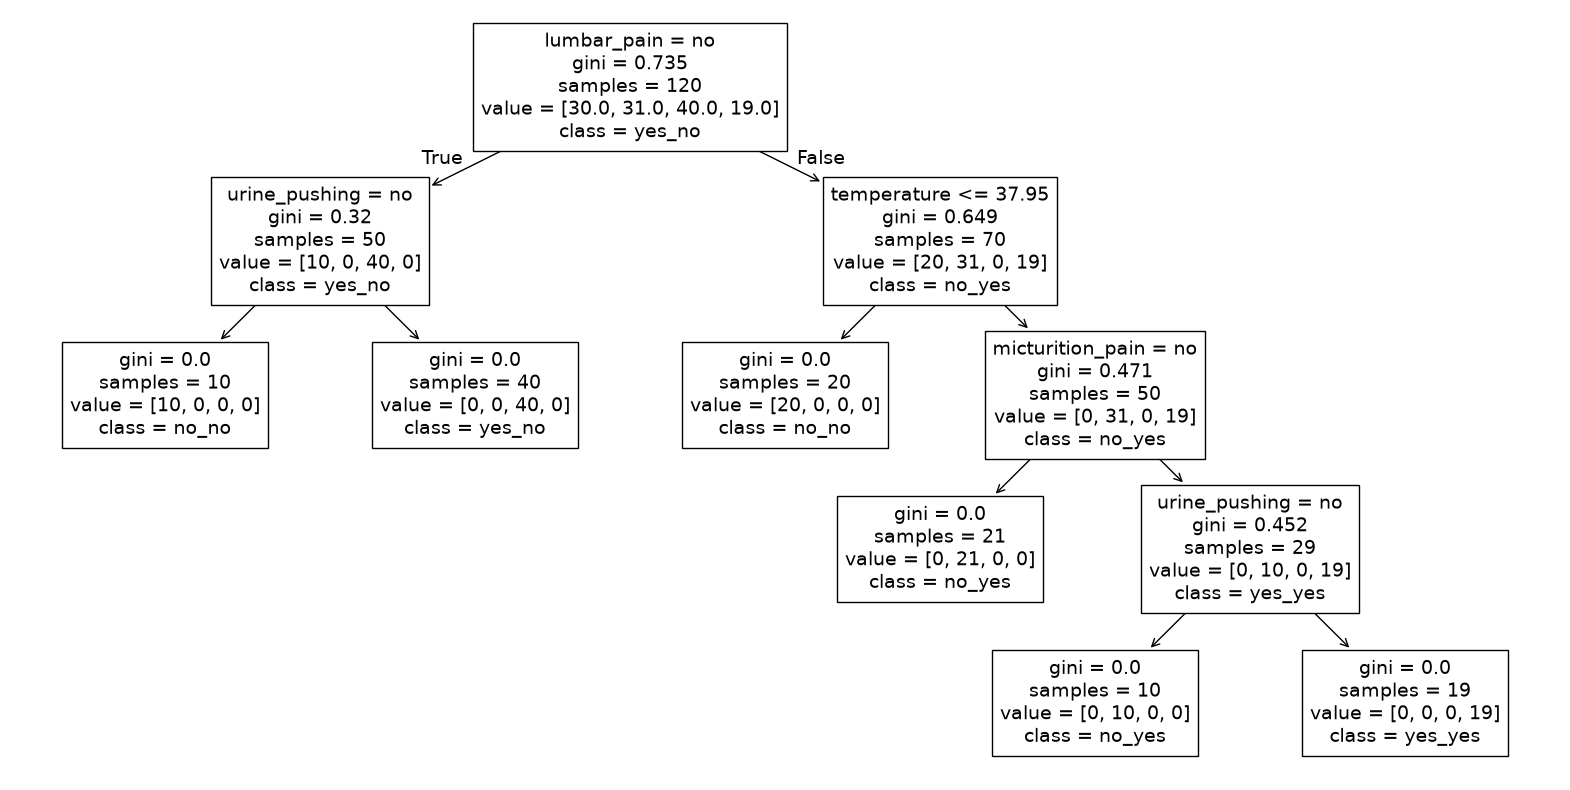

In [3]:
# The two targets are combined as `bladderInflammation_nephritis`
X = acute.iloc[:, :6].replace({"no": 0, "yes": 1})
y = acute.iloc[:, 6] + "_" + acute.iloc[:, 7]

tree = DecisionTreeClassifier(random_state=552)
tree.fit(X, y)

plt.figure(figsize=(20, 10))
nodes = plot_tree(
    tree,
    feature_names=X.columns.tolist(),
    class_names=tree.classes_.tolist()
)

def show_yes_no(nodes, feature_names):
    for node in nodes:
        for feature in feature_names[1:]:
            node.set_text(
                node.get_text().replace(
                    f"{feature} <= 0.5", f"{feature} = no"
                )
            )
show_yes_no(nodes, X.columns)
plt.show()

### (c) Convert the decision rules

In [4]:
def tree_to_pseudo(tree, feature_names):
    t = tree.tree_

    def recurse(node, conditions):
        if t.children_left[node] == -1:
            prediction = tree.classes_[t.value[node][0].argmax()]
            print(f"IF {' AND '.join(conditions)} THEN class = {prediction}")
            return

        feature = feature_names[t.feature[node]]
        threshold = t.threshold[node]

        if feature == "temperature":
            left = f"{feature} <= {threshold:.2f}"
            right = f"{feature} > {threshold:.2f}"
        else:
            left = f"{feature} = no"
            right = f"{feature} = yes"

        recurse(t.children_left[node], conditions + [left])
        recurse(t.children_right[node], conditions + [right])

    recurse(0, [])

print("The two targets are combined as `bladderInflammation_nephritis`. For example, `yes_no` means bladder inflammation is present and nephritis is absent.")
tree_to_pseudo(tree, X.columns.tolist())

The two targets are combined as `bladderInflammation_nephritis`. For example, `yes_no` means bladder inflammation is present and nephritis is absent.
IF lumbar_pain = no AND urine_pushing = no THEN class = no_no
IF lumbar_pain = no AND urine_pushing = yes THEN class = yes_no
IF lumbar_pain = yes AND temperature <= 37.95 THEN class = no_no
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pain = no THEN class = no_yes
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pain = yes AND urine_pushing = no THEN class = no_yes
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pain = yes AND urine_pushing = yes THEN class = yes_yes


### (d) Cost-complexity pruning

Alpha: 0.1
4
0.8416666666666667


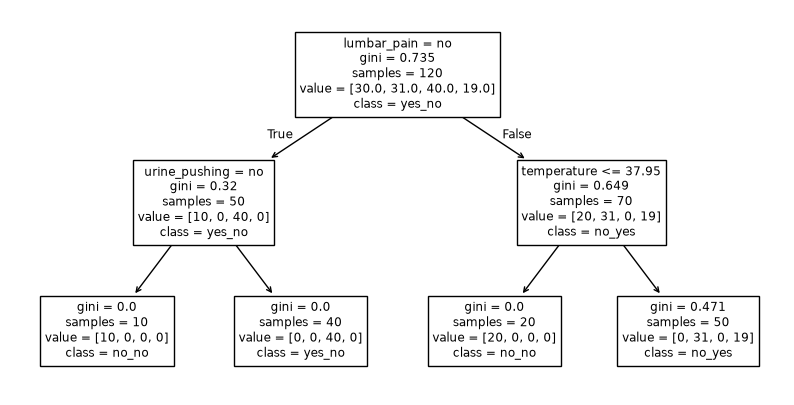

IF lumbar_pain = no AND urine_pushing = no THEN class = no_no
IF lumbar_pain = no AND urine_pushing = yes THEN class = yes_no
IF lumbar_pain = yes AND temperature <= 37.95 THEN class = no_no
IF lumbar_pain = yes AND temperature > 37.95 THEN class = no_yes


In [5]:
alpha = 0.1

pruned_tree = DecisionTreeClassifier(
    ccp_alpha=alpha,
    random_state=552
)
pruned_tree.fit(X, y)

print("Alpha:", alpha)
print(pruned_tree.get_n_leaves())
print(pruned_tree.score(X, y))

plt.figure(figsize=(10, 5))
nodes = plot_tree(
    pruned_tree,
    feature_names=X.columns.tolist(),
    class_names=pruned_tree.classes_.tolist()
)

show_yes_no(nodes, X.columns)

plt.show()
tree_to_pseudo(pruned_tree, X.columns.tolist())

I used 5-fold CV to select alpha, but it selected $\alpha$ = 0, leaving the tree unpruned. To obtain a smaller tree with more interpretable decision rules, I manually set $\alpha$ = 0.1, accepting a trade-off between predictive accuracy and model simplicity.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [6]:
with open("../data/communities+and+crime/communities.names") as f:
    columns = [line.split()[1] for line in f if line.startswith("@attribute")]

crime = pd.read_csv(
    "../data/communities+and+crime/communities.data",
    names=columns,
    na_values="?"
)
train = crime.iloc[:1495]
test = crime.iloc[1495:]
crime.head()

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values

In [7]:
X_train = train.iloc[:, 5:-1]
X_test = test.iloc[:, 5:-1]
y_train = train.iloc[:, -1]
y_test = test.iloc[:, -1]
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

### (c) Plot a correlation matrix

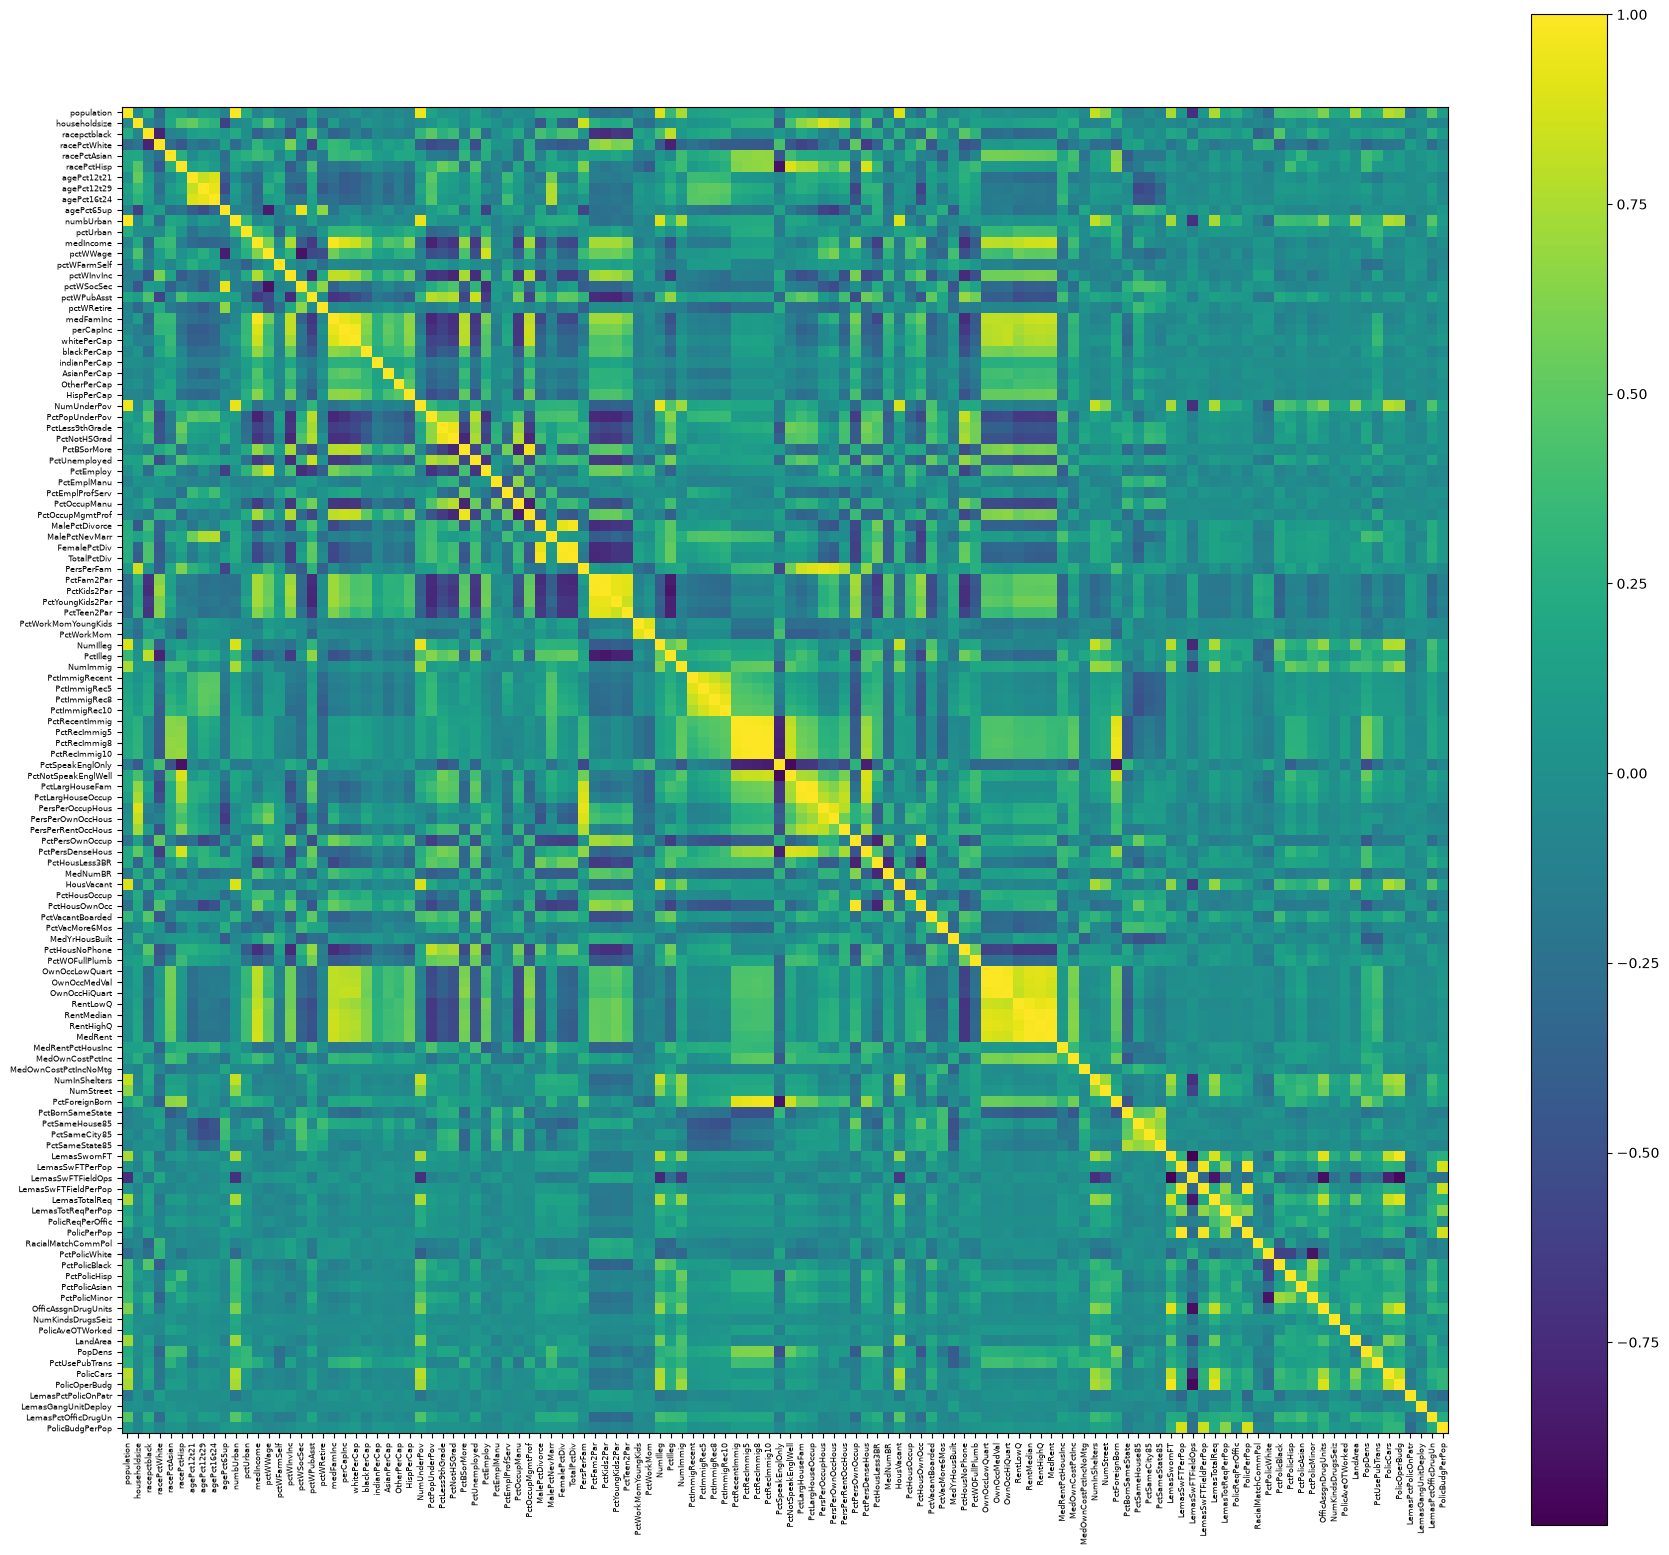

In [8]:
features = pd.concat([X_train, X_test])
corr = features.corr()

plt.figure(figsize=(18, 16))
plt.imshow(corr)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90, fontsize=6)
plt.yticks(range(len(corr)), corr.columns, fontsize=6)
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [9]:
cv = features.std() / features.mean()
print(cv.to_string())

population               2.203503
householdsize            0.353298
racepctblack             1.410920
racePctWhite             0.323782
racePctAsian             1.359162
racePctHisp              1.614278
agePct12t21              0.365840
agePct12t29              0.290693
agePct16t24              0.495161
agePct65up               0.423442
numbUrban                2.001744
pctUrban                 0.638849
medIncome                0.579753
pctWWage                 0.327710
pctWFarmSelf             0.700030
pctWInvInc               0.359240
pctWSocSec               0.368513
pctWPubAsst              0.699031
pctWRetire               0.349639
medFamInc                0.527732
perCapInc                0.545633
whitePerCap              0.507552
blackPerCap              0.589469
indianPerCap             0.809685
AsianPerCap              0.606194
OtherPerCap              0.670691
HispPerCap               0.473960
NumUnderPov              2.304970
PctPopUnderPov           0.753980
PctLess9thGrad

### (e) Scatter plots and box plots for highest CV features

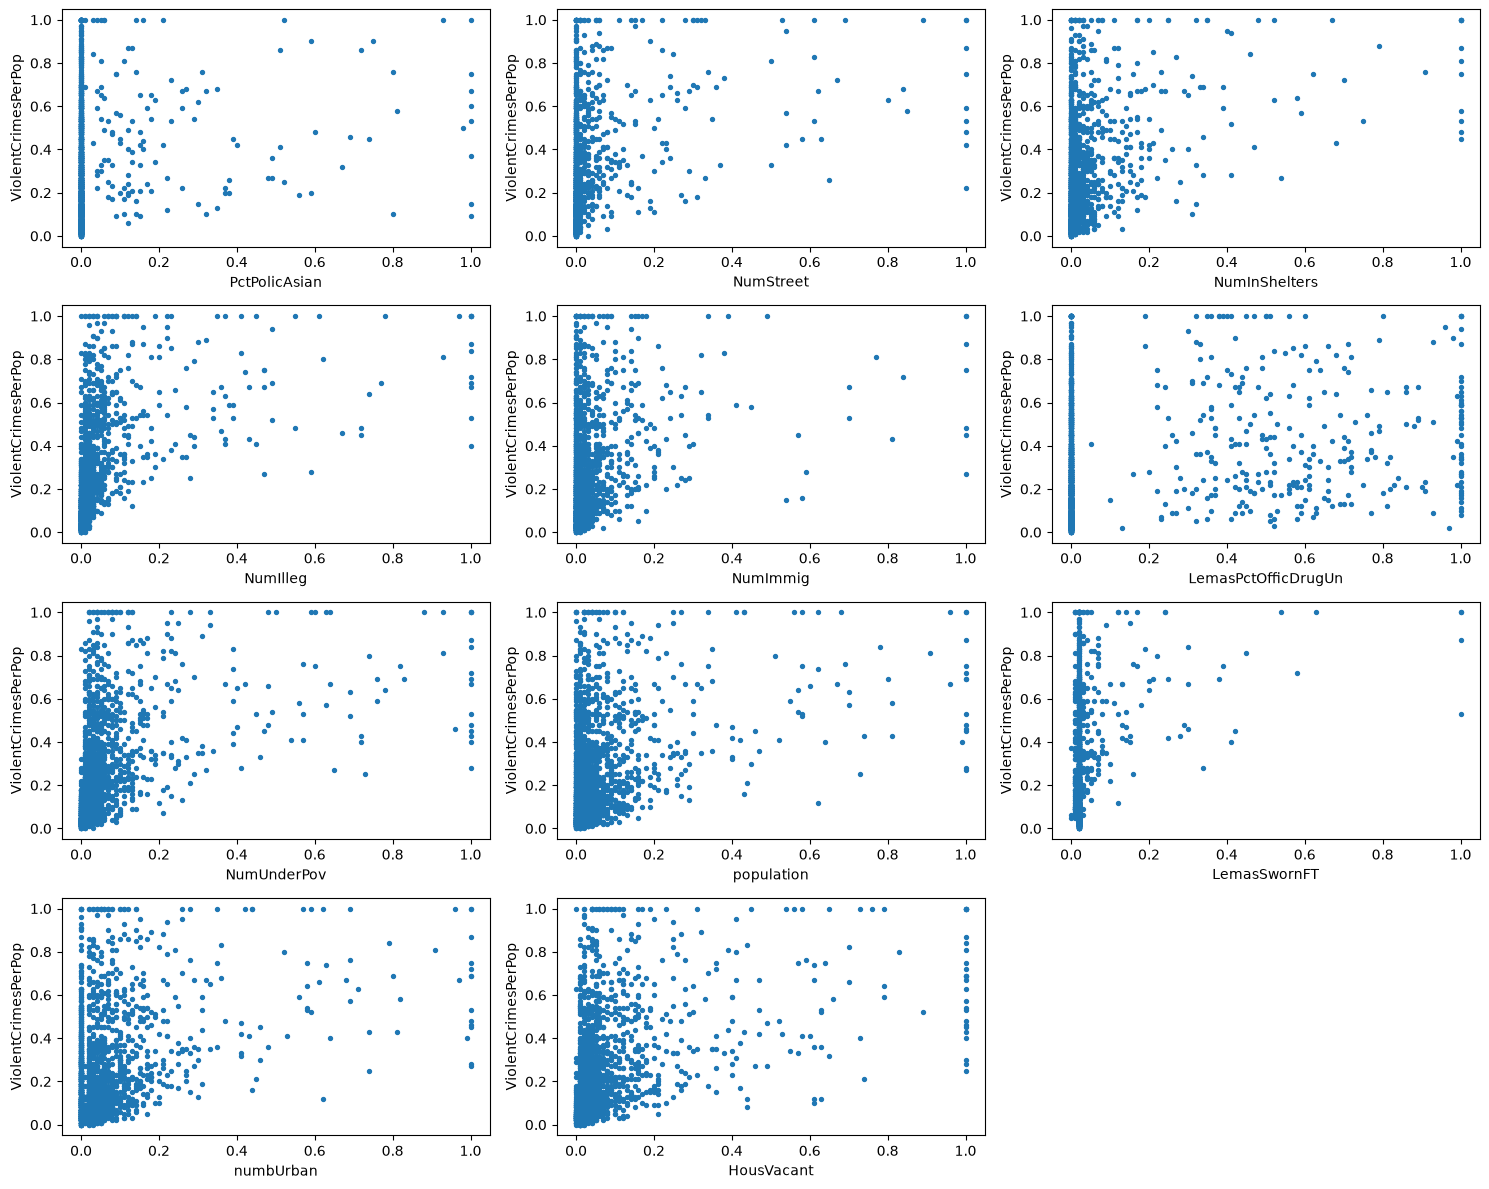

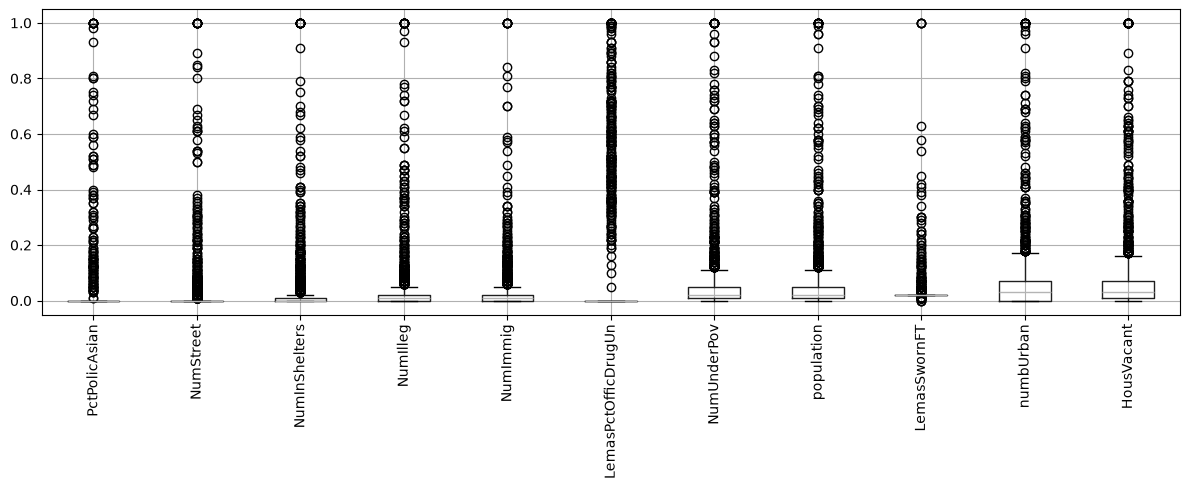

In [10]:
selected = cv.nlargest(11).index
target = pd.concat([y_train, y_test])

plt.figure(figsize=(15, 12))
for i, feature in enumerate(selected, 1):
    plt.subplot(4, 3, i)
    plt.scatter(features[feature], target, s=8)
    plt.xlabel(feature)
    plt.ylabel("ViolentCrimesPerPop")

plt.tight_layout()
plt.show()

features[selected].boxplot(figsize=(12, 5), rot=90)
plt.tight_layout()
plt.show()

No. Scatter plots can show possible relationships, but they cannot tell us whether a feature is statistically significant. We need statistical tests to check this.

### (f) Fit a linear model

In [11]:
linear = LinearRegression()
linear.fit(X_train, y_train)

prediction = linear.predict(X_test)
print("Test MSE:", mean_squared_error(y_test, prediction))

Test MSE: 0.017966215426067342


### (g) Fit a ridge regression model

In [12]:
model = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("ridge", Ridge())
])
parameters = {
    "ridge__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
search = GridSearchCV(
    model,
    parameters,
    cv=5,
    scoring="neg_mean_squared_error"
)
search.fit(train.iloc[:, 5:-1], y_train)
prediction = search.predict(test.iloc[:, 5:-1])
test_error = mean_squared_error(y_test, prediction)

print("lambda:", search.best_params_["ridge__alpha"])
print("Test MSE:", test_error)

lambda: 1
Test MSE: 0.017628245706780225


### (h) Fit a LASSO model

In [13]:
parameters = {"lasso__alpha": np.logspace(-5, 0, 50)}

model = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("lasso", Lasso(max_iter=10000))
])

lasso = GridSearchCV(
    model, parameters, cv=5, scoring="neg_mean_squared_error"
)
lasso.fit(train.iloc[:, 5:-1], y_train)

prediction = lasso.predict(test.iloc[:, 5:-1])
mse_original = mean_squared_error(y_test, prediction)

coef = lasso.best_estimator_.named_steps["lasso"].coef_
selected = X_train.columns[coef != 0].tolist()

print("Original test MSE:", mse_original)
print("Selected variables:", selected)

model_std = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("lasso", Lasso(max_iter=10000))
])

lasso_std = GridSearchCV(
    model_std, parameters, cv=5, scoring="neg_mean_squared_error"
)
lasso_std.fit(train.iloc[:, 5:-1], y_train)

prediction = lasso_std.predict(test.iloc[:, 5:-1])
mse_std = mean_squared_error(y_test, prediction)

coef = lasso_std.best_estimator_.named_steps["lasso"].coef_
selected_std = X_train.columns[coef != 0].tolist()

print("Standardized test MSE:", mse_std)
print("Selected variables:", selected_std)

Original test MSE: 0.01760546583093673
Selected variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet'

The test MSE was 0.017605 before standardization and 0.017661 after standardization. The error increased slightly, so standardization did not improve the model’s test performance in this case.

### (i) Fit a PCR model

In [14]:
model = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("pca", PCA()),
    ("linear", LinearRegression())
])

parameters = {
    "pca__n_components": range(1, X_train.shape[1] + 1)
}

pcr = GridSearchCV(
    model, parameters, scoring="neg_mean_squared_error"
)
pcr.fit(train.iloc[:, 5:-1], y_train)

prediction = pcr.predict(test.iloc[:, 5:-1])

print("Selected M:", pcr.best_params_["pca__n_components"])
print("Test MSE:", mean_squared_error(y_test, prediction))

Selected M: 95
Test MSE: 0.018296345367709833


### (j) Fit a boosting tree

In [15]:
model = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("xgb", XGBRegressor(random_state=552))
])

parameters = {
    "xgb__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 100]
}

boost = GridSearchCV(
    model, parameters, scoring="neg_mean_squared_error"
)
boost.fit(train.iloc[:, 5:-1], y_train)

print("Selected alpha:", boost.best_params_["xgb__reg_alpha"])

Selected alpha: 1
